In [1]:
import time
import warnings
from pprint import PrettyPrinter

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import pytz
import seaborn as sns
from pymongo import MongoClient
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA

warnings.simplefilter(action="ignore", category=FutureWarning)
pp = PrettyPrinter(indent=2)


In [2]:
host = "192.225.148.2"
client = MongoClient(host=host, port=27017)
db = client["air-quality"]
nairobi = db["nairobi"]


In [3]:
pp.pprint(list(client.list_databases()))

[ {'empty': False, 'name': 'admin', 'sizeOnDisk': 40960},
  {'empty': False, 'name': 'air-quality', 'sizeOnDisk': 5976064},
  {'empty': False, 'name': 'config', 'sizeOnDisk': 73728},
  {'empty': False, 'name': 'local', 'sizeOnDisk': 73728},
  {'empty': False, 'name': 'wqu-abtest', 'sizeOnDisk': 585728}]


In [4]:
[c["name"] for c in db.list_collections()]

['dar-es-salaam',
 'system.buckets.dar-es-salaam',
 'nairobi',
 'system.buckets.nairobi',
 'system.views',
 'lagos',
 'system.buckets.lagos']

In [5]:
nairobi.count_documents({})

202212

In [6]:
result = nairobi.find_one({})
pp.pprint(result)

{ '_id': ObjectId('6525d772f44bfedd842a6fcc'),
  'metadata': { 'lat': -1.3,
                'lon': 36.785,
                'measurement': 'temperature',
                'sensor_id': 58,
                'sensor_type': 'DHT22',
                'site': 29},
  'temperature': 16.5,
  'timestamp': datetime.datetime(2018, 9, 1, 0, 0, 4, 301000)}


In [7]:
nairobi.distinct("metadata.site")

[29, 6]

In [8]:
print("Documents from site 6:", nairobi.count_documents({"metadata.site" : 6}))
print("Documents from site 29:", nairobi.count_documents({"metadata.site" : 29}))

Documents from site 6: 70360
Documents from site 29: 131852


In [9]:
result = nairobi.aggregate(
    [
        {"$group" : {"_id" : "$metadata.site", "count" : {"$count" : {}}}}
    ]
)
pp.pprint(list(result))

[{'_id': 6, 'count': 70360}, {'_id': 29, 'count': 131852}]


In [10]:
nairobi.distinct("metadata.measurement")

['P1', 'humidity', 'temperature', 'P2']

In [11]:
result = nairobi.find({"metadata.measurement" : "P2"}).limit(3)
pp.pprint(list(result))

[ { 'P2': 34.43,
    '_id': ObjectId('6525d775f44bfedd842bf24d'),
    'metadata': { 'lat': -1.3,
                  'lon': 36.785,
                  'measurement': 'P2',
                  'sensor_id': 57,
                  'sensor_type': 'SDS011',
                  'site': 29},
    'timestamp': datetime.datetime(2018, 9, 1, 0, 0, 2, 472000)},
  { 'P2': 30.53,
    '_id': ObjectId('6525d775f44bfedd842bf24e'),
    'metadata': { 'lat': -1.3,
                  'lon': 36.785,
                  'measurement': 'P2',
                  'sensor_id': 57,
                  'sensor_type': 'SDS011',
                  'site': 29},
    'timestamp': datetime.datetime(2018, 9, 1, 0, 5, 3, 941000)},
  { 'P2': 22.8,
    '_id': ObjectId('6525d775f44bfedd842bf24f'),
    'metadata': { 'lat': -1.3,
                  'lon': 36.785,
                  'measurement': 'P2',
                  'sensor_id': 57,
                  'sensor_type': 'SDS011',
                  'site': 29},
    'timestamp': datetime.datetime(

Breakdown of measurements at **Site 6** versus **Site 29** using `$match` and `$group` aggregation pipelines:

In [12]:
result = nairobi.aggregate(
    [
        {"$match" : {"metadata.site" : 6}},
        {"$group" : {"_id" : "$metadata.measurement", "count" : {"$count" : {}}}}
    ]
)
pp.pprint(list(result))

[ {'_id': 'humidity', 'count': 17011},
  {'_id': 'P1', 'count': 18169},
  {'_id': 'P2', 'count': 18169},
  {'_id': 'temperature', 'count': 17011}]


In [13]:
result = nairobi.aggregate(
    [
        {"$match" : {"metadata.site" : 29}},
        {"$group" : {"_id" : "$metadata.measurement", "count" : {"$count" : {}}}}
    ]
)
pp.pprint(list(result))

[ {'_id': 'P1', 'count': 32907},
  {'_id': 'humidity', 'count': 33019},
  {'_id': 'temperature', 'count': 33019},
  {'_id': 'P2', 'count': 32907}]


In [14]:
result = nairobi.find({"metadata.site" : 29, "metadata.measurement" : "P2"}, projection={"P2":1,"timestamp":1,"_id":0})
pp.pprint(result.next())

{'P2': 34.43, 'timestamp': datetime.datetime(2018, 9, 1, 0, 0, 2, 472000)}


In [15]:
df = pd.DataFrame(result).set_index("timestamp")
df.head()

,P2
timestamp,
2018-09-01 00:05:03.941,30.53
2018-09-01 00:10:04.374,22.80
2018-09-01 00:15:04.245,13.30
2018-09-01 00:20:04.869,16.57
2018-09-01 00:25:04.659,14.07


In [16]:
def wrangle_lag_df(collection):
    results = collection.find(
        {"metadata.site": 29, "metadata.measurement": "P2"},
        projection={"P2": 1, "timestamp": 1, "_id": 0},
    )

    df = pd.DataFrame(results).set_index("timestamp")

    # Localize UTC timestamps to East Africa Time
    df = df.tz_localize("UTC").tz_convert("Africa/Nairobi")

    # Remove extreme sensor outliers
    df = df[df["P2"] < 500]

    # Resample to 1-hour mean windows and forward-fill short gaps
    df = df["P2"].resample("1H").mean().fillna(method="ffill").to_frame()

    # Create 1-hour lag feature
    df["P2.L1"] = df["P2"].shift(1)
    df.dropna(inplace=True)

    return df


In [17]:
df = wrangle_lag_df(nairobi)
df.head()

,P2,P2.L1
timestamp,,
2018-09-01 04:00:00+03:00,15.800000,17.541667
2018-09-01 05:00:00+03:00,11.420000,15.800000
2018-09-01 06:00:00+03:00,11.614167,11.420000
2018-09-01 07:00:00+03:00,17.665000,11.614167
2018-09-01 08:00:00+03:00,21.016667,17.665000


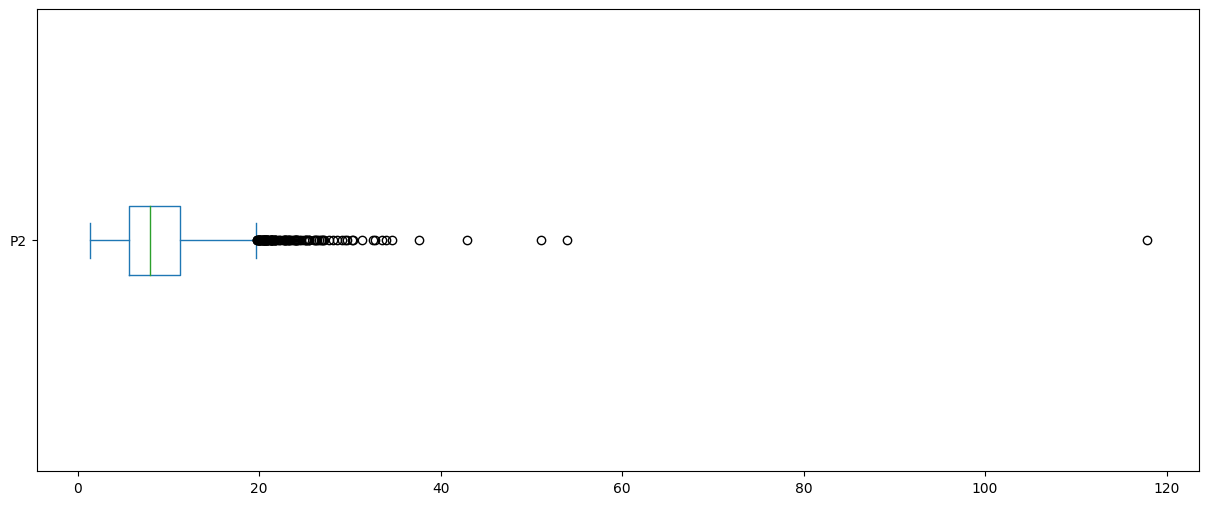

In [18]:
fig, ax = plt.subplots(figsize=(15, 6))

df["P2"].plot(kind="box", vert=False, ax=ax );

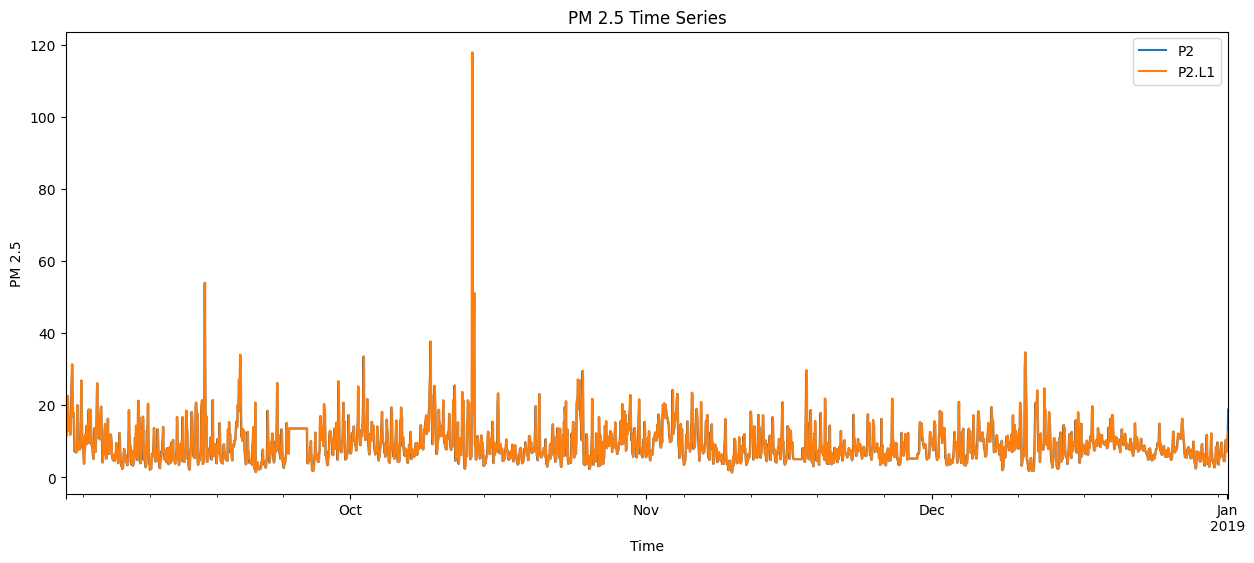

In [19]:
fig, ax = plt.subplots(figsize=(15, 6))

df.plot(ax=ax, xlabel="Time", ylabel="PM 2.5", title="PM 2.5 Time Series");

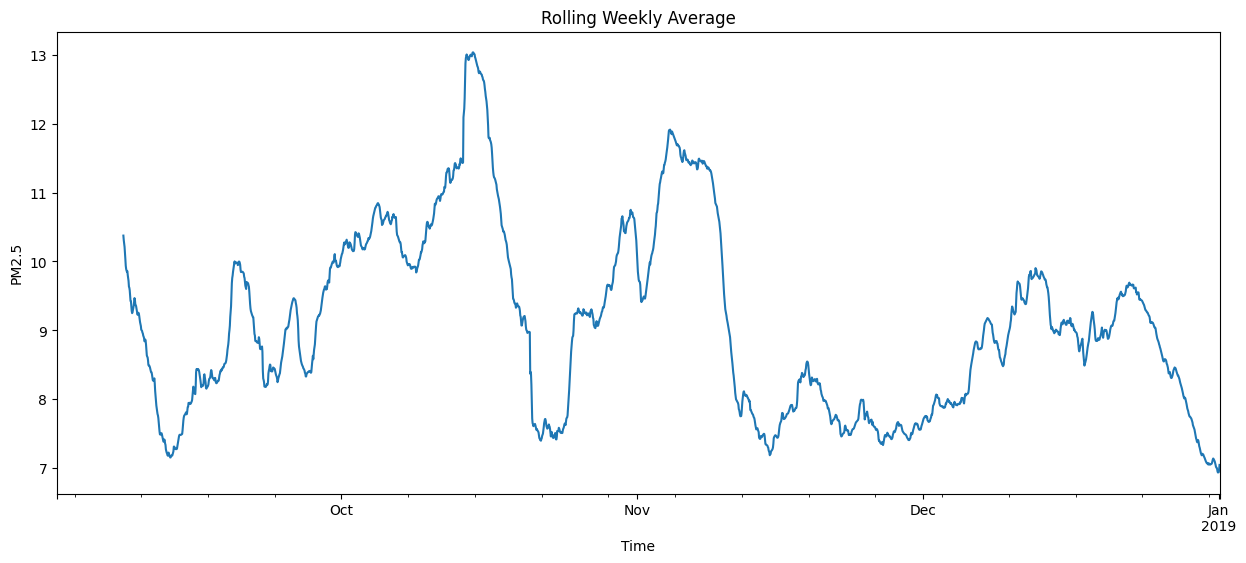

In [20]:
fig, ax = plt.subplots(figsize=(15, 6))

df["P2"].rolling(168).mean().plot(ax=ax,title="Rolling Weekly Average",ylabel="PM2.5",xlabel="Time");

In [21]:
df.corr()

,P2,P2.L1
P2,1.000000,0.650679
P2.L1,0.650679,1.000000


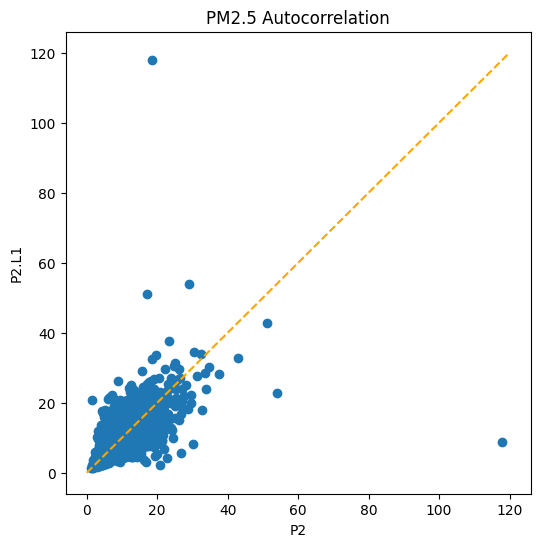

In [22]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(x=df["P2"], y=df["P2.L1"])
plt.plot([0,120], [0,120], linestyle="--", color="orange")
plt.xlabel("P2")
plt.ylabel("P2.L1")
plt.title("PM2.5 Autocorrelation");

In [23]:
target = "P2"
y = df[target]
X = df.drop(columns=target)

In [24]:
cutoff = int(0.8 * len(X))

X_train, y_train = X.iloc[:cutoff], y.iloc[:cutoff]
X_test, y_test = X.iloc[cutoff:], y.iloc[cutoff:]

In [25]:
y_pred_baseline = [y_train.mean()] * len(y_train)
mae_baseline = mean_absolute_error(y_train, y_pred_baseline)

print("Mean P2 Reading:", round(y_train.mean(), 2))
print("Baseline MAE:", round(mae_baseline, 2))


Mean P2 Reading: 9.27
Baseline MAE: 3.89


In [26]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

LinearRegression()

In [27]:
training_mae = mean_absolute_error(y_train, model_lr.predict(X_train))
test_mae = mean_absolute_error(y_test, model_lr.predict(X_test))
print("Training MAE:", round(training_mae, 2))
print("Test MAE:", round(test_mae, 2))


Training MAE: 2.46
Test MAE: 1.8


In [28]:
intercept = model_lr.intercept_.round(2)
coefficient = model_lr.coef_[0].round(2)

print(f"P2 = {intercept} + ({coefficient} * P2.L1)")


P2 = 3.36 + ([0.64] * P2.L1)


In [29]:
df_pred_test = pd.DataFrame(
    {
        "y_test": y_test,
        "y_pred": model_lr.predict(X_test),
    }
)
df_pred_test.head()


,y_test,y_pred
timestamp,,
2018-12-07 17:00:00+03:00,7.070000,8.478927
2018-12-07 18:00:00+03:00,8.968333,7.865485
2018-12-07 19:00:00+03:00,11.630833,9.076421
2018-12-07 20:00:00+03:00,11.525833,10.774814
2018-12-07 21:00:00+03:00,9.533333,10.707836


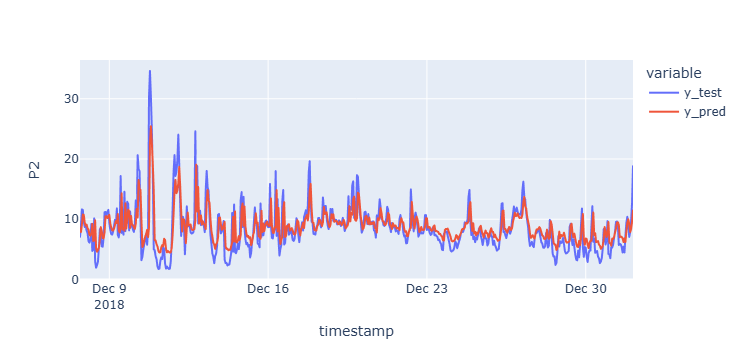

In [30]:
fig = px.line(df_pred_test, labels={"value":"P2"})
fig.show()

In [31]:
def wrangle(collection, resample_rule="1H"):
    results = collection.find(
        {"metadata.site": 29, "metadata.measurement": "P2"},
        projection={"P2": 1, "timestamp": 1, "_id": 0},
    )

    # Read results into DataFrame
    df = pd.DataFrame(list(results)).set_index("timestamp")

    # Localize timezone
    df.index = df.index.tz_localize("UTC").tz_convert("Africa/Nairobi")

    # Remove outliers
    df = df[df["P2"] < 500]

    # Resample and forward-fill
    y = df["P2"].resample(resample_rule).mean().fillna(method="ffill")

    return y

In [32]:
y = wrangle(nairobi)
y.head()

timestamp
2018-09-01 03:00:00+03:00    17.541667
2018-09-01 04:00:00+03:00    15.800000
2018-09-01 05:00:00+03:00    11.420000
2018-09-01 06:00:00+03:00    11.614167
2018-09-01 07:00:00+03:00    17.665000
Freq: H, Name: P2, dtype: float64

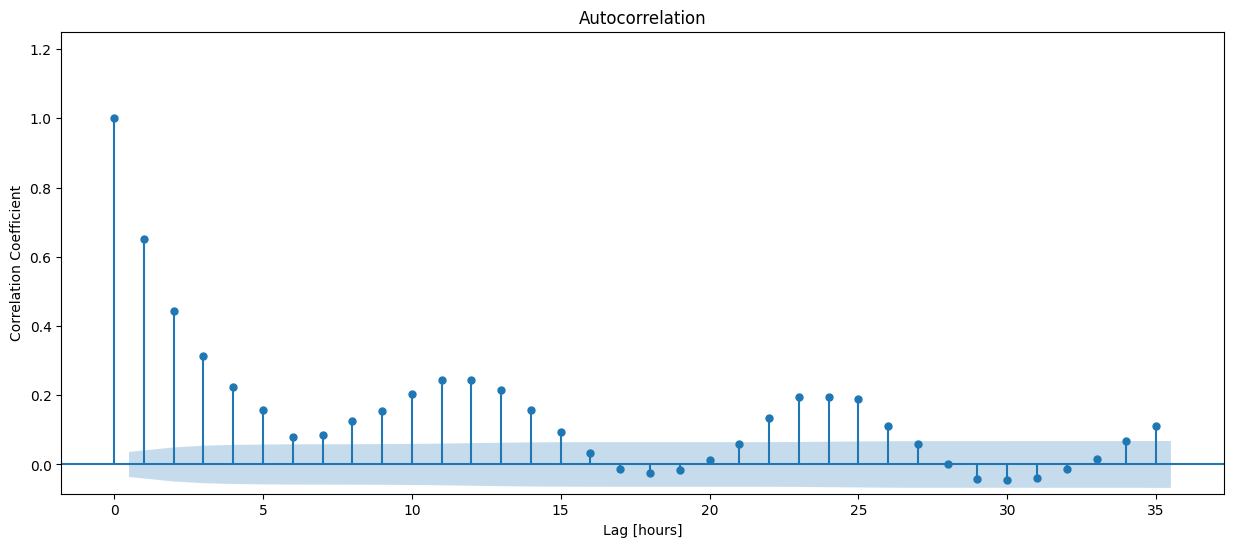

In [33]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_acf(y, ax=ax, auto_ylims=True)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient");

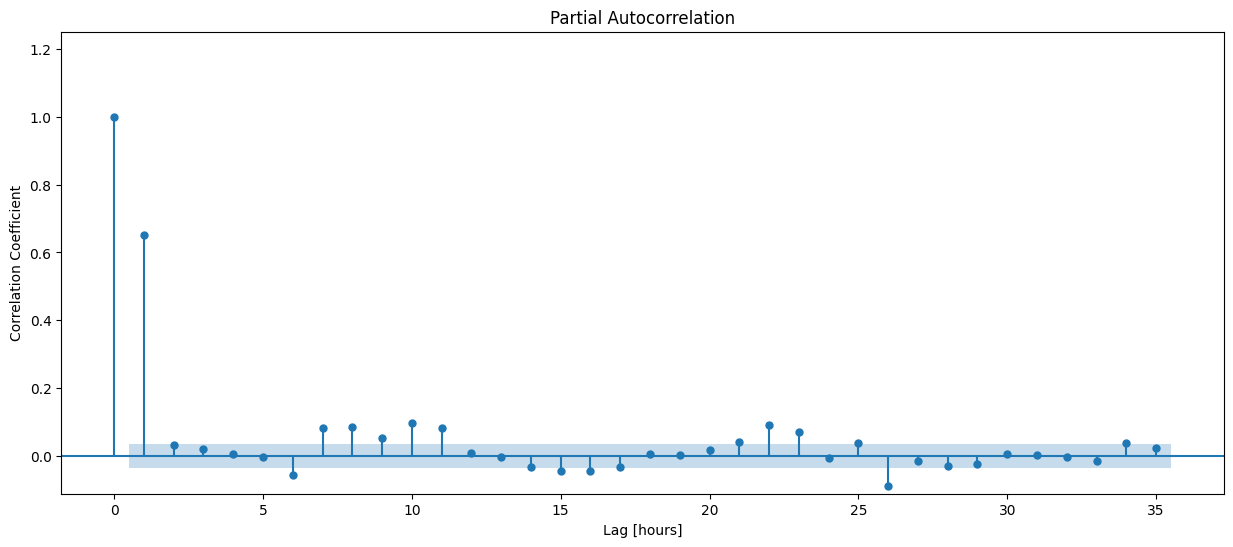

In [34]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_pacf(y, ax=ax, auto_ylims=True)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient");

In [35]:
cutoff_test = int(0.95 * len(y))

y_train = y.iloc[:cutoff_test]
y_test = y.iloc[cutoff_test:]

In [36]:
y_train_mean = y_train.mean()
y_pred_baseline = [y_train_mean] * len(y_train)
mae_baseline = mean_absolute_error(y_train, y_pred_baseline)

print("Mean P2 Reading:", round(y_train_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))

Mean P2 Reading: 9.22
Baseline MAE: 3.71


In [37]:
model_ar = AutoReg(y_train, lags=26).fit()

In [38]:
y_pred = model_ar.predict().dropna()
training_mae = mean_absolute_error(y_train.iloc[26:], y_pred)
print("Training MAE:", training_mae)


Training MAE: 2.2809871656467


In [39]:
y_train_resid = model_ar.resid
y_train_resid.tail()

timestamp
2018-12-25 19:00:00+03:00   -0.392002
2018-12-25 20:00:00+03:00   -1.573180
2018-12-25 21:00:00+03:00   -0.735747
2018-12-25 22:00:00+03:00   -2.022221
2018-12-25 23:00:00+03:00   -0.061916
Freq: H, dtype: float64

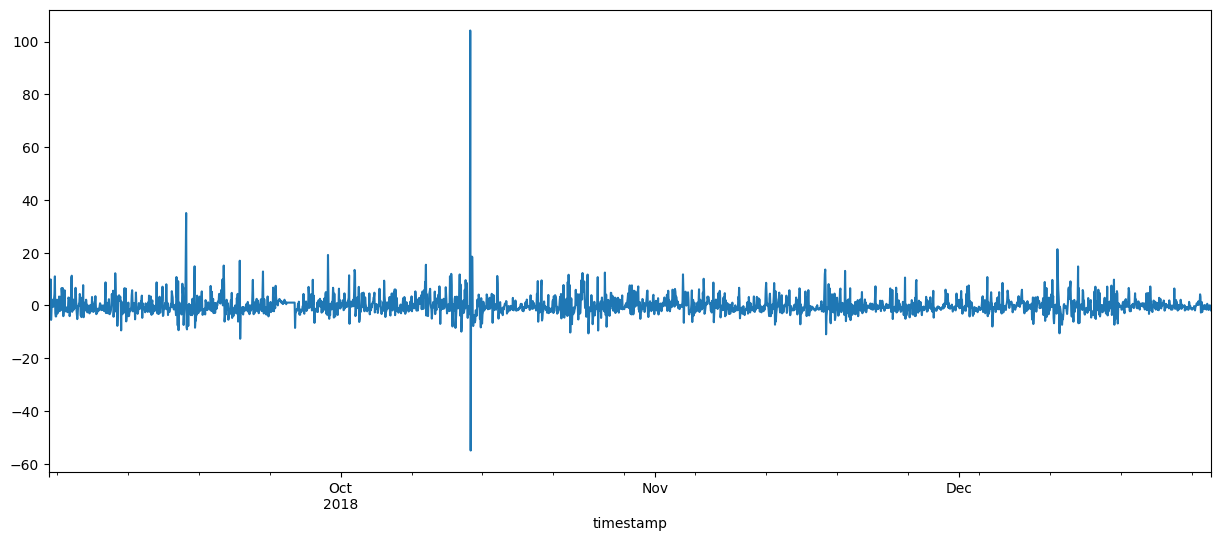

In [40]:
fig, ax = plt.subplots(figsize=(15, 6))
y_train_resid.plot(ax=ax);

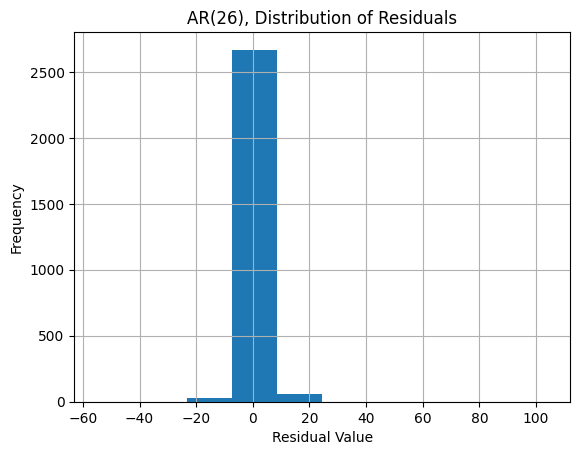

In [41]:
y_train_resid.hist()
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.title("AR(26), Distribution of Residuals");

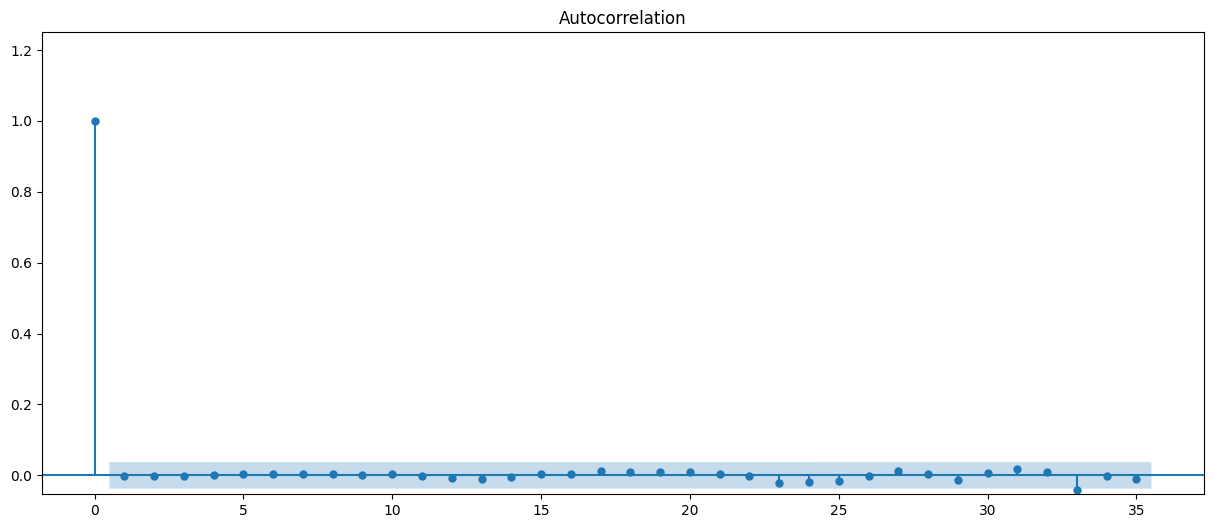

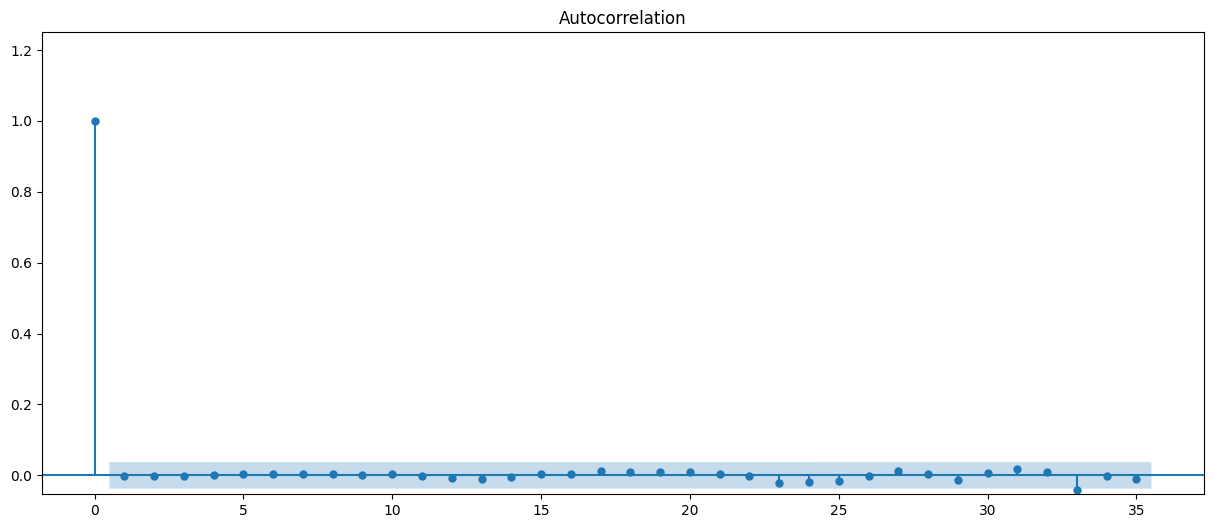

In [42]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_acf(y_train_resid, ax=ax, auto_ylims=True)

In [43]:
y_pred_test = model_ar.predict(y_test.index.min(), y_test.index.max())
test_mae_static = mean_absolute_error(y_test, y_pred_test)
print("Test MAE (static multi-step):", round(test_mae_static, 2))


Test MAE: 3.013643949503859


In [44]:
df_pred_test = pd.DataFrame(
    {"y_test": y_test, "y_pred": y_pred_test}, index=y_test.index
)

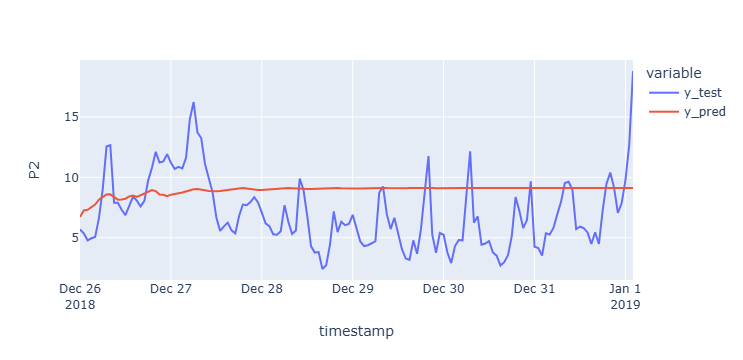

In [45]:
fig = px.line(df_pred_test, labels={"value": "P2"})
fig.show()

In [46]:
%%capture

y_pred_wfv = pd.Series(dtype=float)
history = y_train.copy()
for i in range(len(y_test)):
    model_wfv = AutoReg(history, lags=26).fit()
    next_pred = model_wfv.forecast()
    y_pred_wfv = pd.concat([y_pred_wfv, next_pred])
    history = pd.concat([history, y_test[next_pred.index]])


In [47]:
test_mae = mean_absolute_error(y_test, y_pred_wfv)
print("Test MAE (walk forward validation):", round(test_mae, 2))

Test MAE (walk forward validation): 1.4


In [48]:
print(model_wfv.params)

const     2.011432
P2.L1     0.587118
P2.L2     0.019796
P2.L3     0.023615
P2.L4     0.027187
P2.L5     0.044014
P2.L6    -0.102128
P2.L7     0.029583
P2.L8     0.049867
P2.L9    -0.016897
P2.L10    0.032438
P2.L11    0.064360
P2.L12    0.005987
P2.L13    0.018375
P2.L14   -0.007636
P2.L15   -0.016075
P2.L16   -0.015953
P2.L17   -0.035444
P2.L18    0.000756
P2.L19   -0.003907
P2.L20   -0.020655
P2.L21   -0.012578
P2.L22    0.052499
P2.L23    0.074229
P2.L24   -0.023806
P2.L25    0.090577
P2.L26   -0.088323
dtype: float64


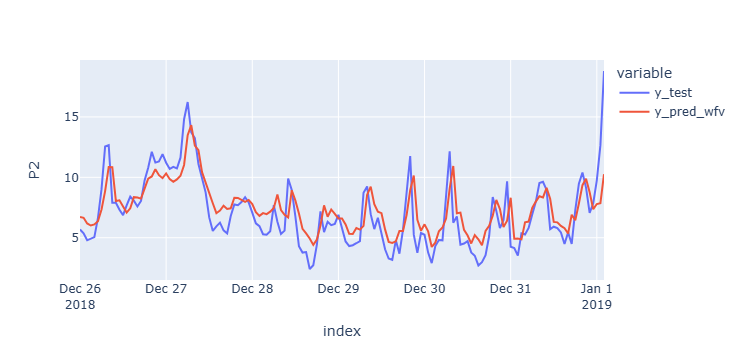

In [49]:
df_pred_test = pd.DataFrame(
    {"y_test":y_test, "y_pred_wfv":y_pred_wfv}
)

fig = px.line(df_pred_test, labels={"value":"P2"})
fig.show()

In [50]:
y_train_arma = y.loc["2018-10"]
y_test_arma = y.loc["2018-11-1"]
print("Train shape:", y_train_arma.shape)
print("Test shape:", y_test_arma.shape)


(744,)
(24,)


In [51]:
y_train_mean = y_train_arma.mean()
y_pred_baseline = [y_train_mean] * len(y_train_arma)
mae_baseline = mean_absolute_error(y_train_arma, y_pred_baseline)

print("Mean P2 Reading:", round(y_train_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))


Mean P2 Reading: 10.12
Baseline MAE: 4.17


In [52]:
p_params = range(0,25,8)
q_params = range(0,3)

In [53]:
# Dictionary to store training MAEs for each (p, q) pair
mae_grid = {}

for p in p_params:
    mae_grid[p] = []
    for q in q_params:
        order = (p, 0, q)
        start_time = time.time()
        model_arma = ARIMA(y_train_arma, order=order).fit()
        elapsed_time = round(time.time() - start_time, 2)
        print(f"Trained ARIMA {order} in {elapsed_time} seconds.")

        y_pred = model_arma.predict()
        mae = mean_absolute_error(y_train_arma, y_pred)
        mae_grid[p].append(mae)

print()
print(mae_grid)


Trained ARIMA (0, 0, 0) in 0.15 seconds.
Trained ARIMA (0, 0, 1) in 0.1 seconds.
Trained ARIMA (0, 0, 2) in 0.45 seconds.
Trained ARIMA (8, 0, 0) in 0.33 seconds.
Trained ARIMA (8, 0, 1) in 1.03 seconds.
Trained ARIMA (8, 0, 2) in 1.22 seconds.
Trained ARIMA (16, 0, 0) in 0.9 seconds.
Trained ARIMA (16, 0, 1) in 3.05 seconds.
Trained ARIMA (16, 0, 2) in 3.87 seconds.
Trained ARIMA (24, 0, 0) in 5.31 seconds.
Trained ARIMA (24, 0, 1) in 7.06 seconds.
Trained ARIMA (24, 0, 2) in 12.43 seconds.

{0: [4.171460443827197, 3.3506427433167634, 3.1057222588243443], 8: [2.9384480570053584, 2.9149013330115974, 2.9132458963032315], 16: [2.9201084725449653, 2.9294363113458335, 2.9120798462337034], 24: [2.914390327410196, 2.9136013236816525, 2.8979121370798664]}


In [54]:
mae_df = pd.DataFrame(mae_grid)
mae_df.round(4)

,0,8,16,24
0,4.1715,2.9384,2.9201,2.9144
1,3.3506,2.9149,2.9294,2.9136
2,3.1057,2.9132,2.9121,2.8979


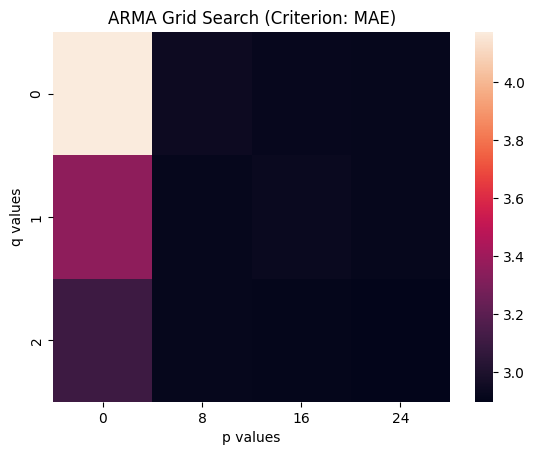

In [55]:
sns.heatmap(mae_df)

plt.xlabel("p values")
plt.ylabel("q values")
plt.title("ARMA Grid Search (Criterion: MAE)");

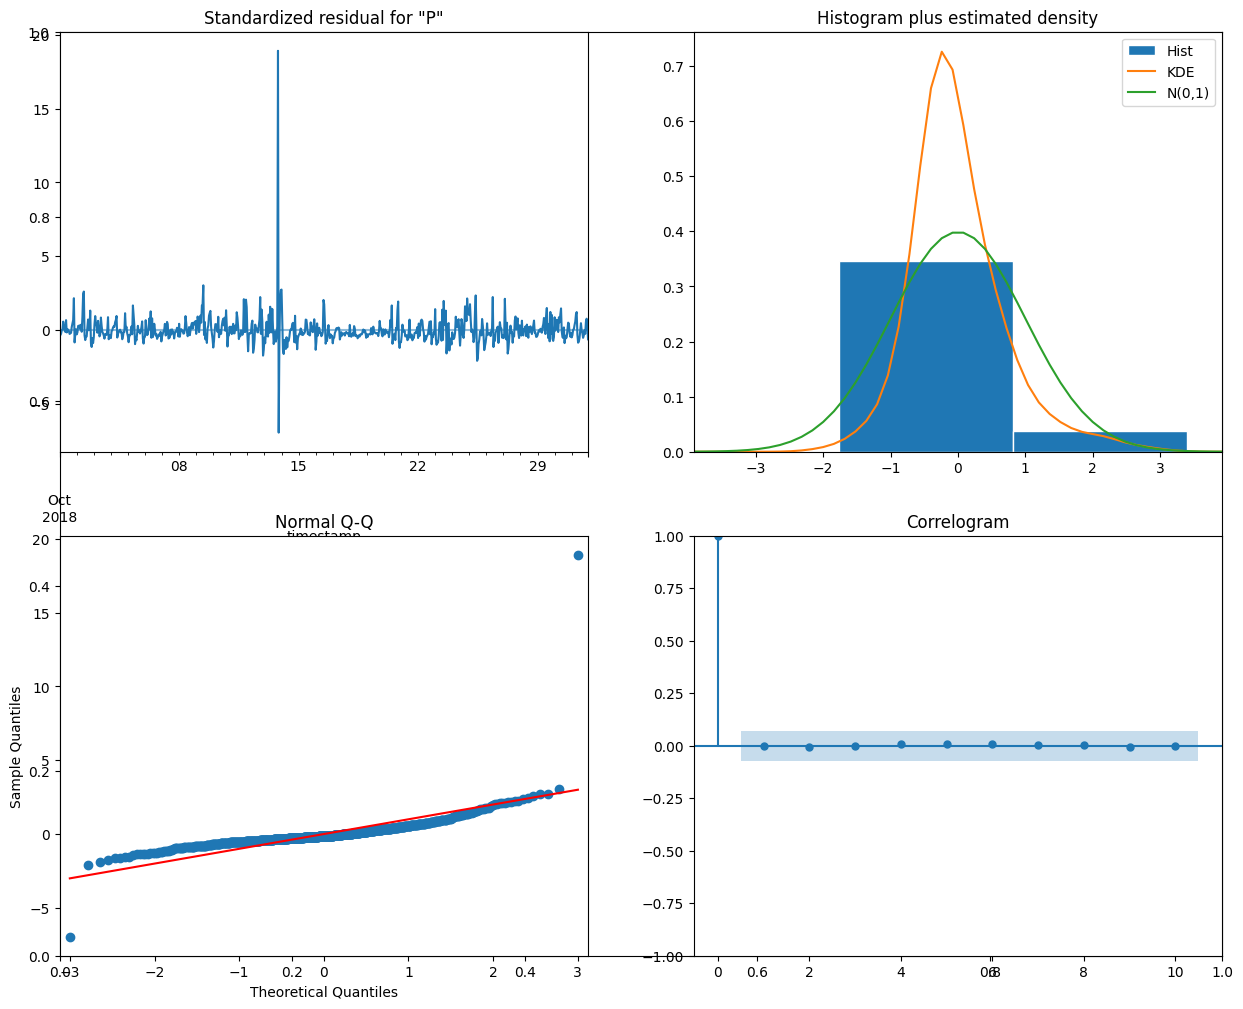

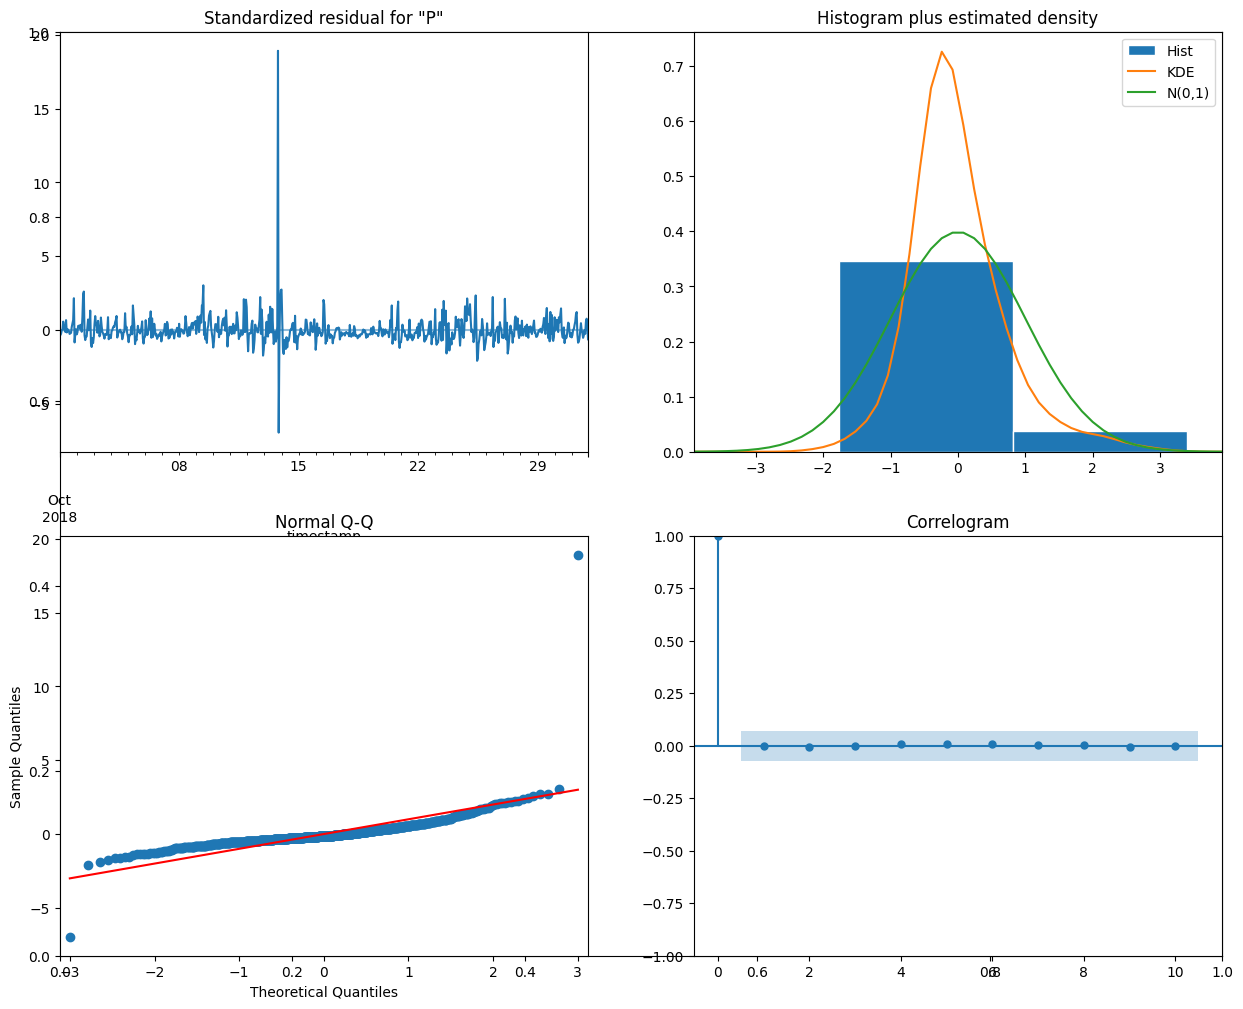

In [56]:
fig, ax = plt.subplots(figsize=(15, 12))
model_arma.plot_diagnostics(fig=fig);

In [57]:
%%capture

y_pred_wfv_arma = pd.Series(dtype=float)
history = y_train_arma.copy()
for i in range(len(y_test_arma)):
    model_step = ARIMA(history, order=(8, 0, 1)).fit()
    next_pred = model_step.forecast()
    y_pred_wfv_arma = pd.concat([y_pred_wfv_arma, next_pred])
    history = pd.concat([history, y_test_arma[next_pred.index]])


In [58]:
test_mae_arma = mean_absolute_error(y_test_arma, y_pred_wfv_arma)
print("Test MAE (walk forward validation):", round(test_mae_arma, 2))


Test MAE (walk forward validation): 1.67


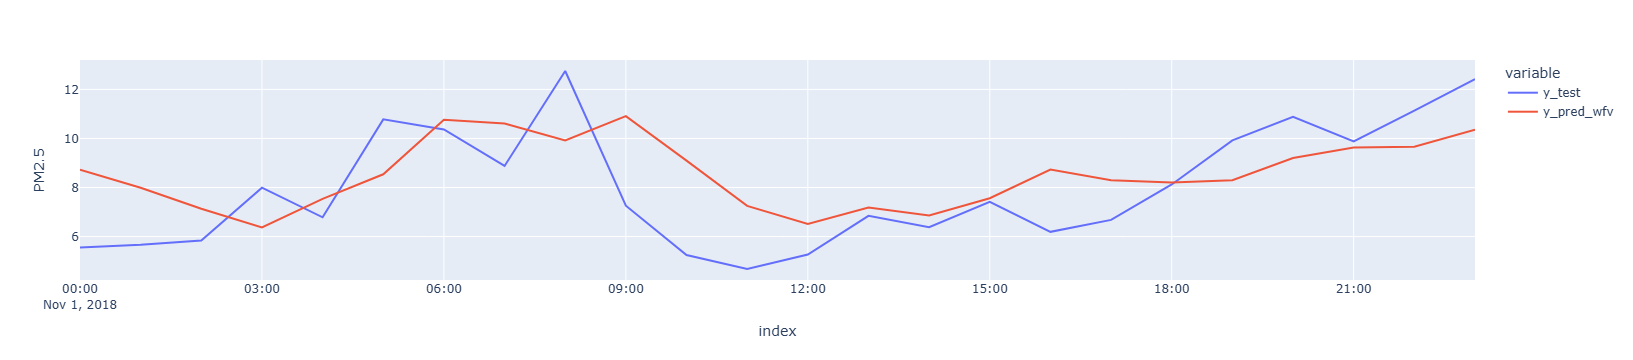

In [59]:
df_predictions = pd.DataFrame({"y_test": y_test_arma, "y_pred_wfv": y_pred_wfv_arma})
fig = px.line(df_predictions, labels={"value": "PM2.5"})
fig.show()


---
## 7. Summary & Model Comparison

| Model Specification | Split / Test Window | Baseline MAE | Training MAE | Test MAE | Key Takeaway |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **Lag-1 Linear Regression** (`P2 = 3.36 + 0.64·P2.L1`) | 80/20 Chronological | 3.89 | 2.46 | **1.80** | Strong 1-step baseline; lags sharp spikes by 1 hour. |
| **Static Multi-Step AR(26)** | 95/5 Chronological | 3.71 | 2.28 | **3.01** | Rapidly reverts to series mean without sensor updates. |
| **Walk-Forward AR(26)** | 95/5 Expanding WFV | 3.71 | 2.28 | **1.40** | Best overall accuracy; 62.3% below baseline, 53.5% better than static. |
| **Walk-Forward ARMA(8, 0, 1)** | Oct 2018 / Nov 1 (24h) | 4.17 | 2.91 | **1.67** | Best speed-accuracy trade-off selected via `(p, q)` grid search. |

### Key Engineering Takeaways
- **Server-side NoSQL filtering & projection** (`PyMongo`) keeps local memory usage low when working with 200,000+ sensor documents.
- **Chronological splitting and Walk-Forward Validation** are essential for realistic time-series evaluation—static multi-step forecasts flatten out over multi-day horizons.
- **Parsimonious model selection** (`ARIMA(8, 0, 1)` over `ARIMA(24, 0, 2)`) balances accuracy against re-fitting latency inside iterative validation loops.
